# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd

conso = pd.read_csv("donnees/consommation_brut.csv")
conso.info()
print(conso.isna().sum())
print(conso.duplicated().sum())
conso.head()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mois            300 non-null    str    
 1   quartier        300 non-null    str    
 2   kwh             291 non-null    str    
 3   heures_courant  300 non-null    float64
dtypes: float64(1), str(3)
memory usage: 16.7 KB
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64
12


,mois,quartier,kwh,heures_courant
0,2024-01,Bas-Peu-de-Chose,184410 kWh,10.6
1,2024-02,Bas-Peu-de-Chose,195930,11.9
2,2024-03,Bas-Peu-de-Chose,186560,10.2
3,2024-04,Bas-Peu-de-Chose,236730,12.2
4,2024-05,Bas-Peu-de-Chose,206280 kWh,10.2


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")
quartiers
print(conso["quartier"].nunique())
conso["quartier"].value_counts()

43


quartier
Bois-Verna             24
Petite-Anse            24
Morne Calvaire         23
Delmas 33              22
Delmas 65              22
Carénage               22
Rue 15                 22
Delmas 75              21
Centre-ville           20
Thomassin              20
Place Saint-Pierre     20
Bas-Peu-de-Chose       18
BOIS-VERNA              4
 Morne Calvaire         3
bas-peu-de-chose        2
Bas-Peu-de-Chose        2
centre-ville            2
delmas 65               2
delmas 75               2
Thomassin               2
 Bas-Peu-de-Chose       1
BAS-PEU-DE-CHOSE        1
Centre-ville            1
CENTRE-VILLE            1
Delmas 33               1
 Delmas 33              1
DELMAS 33               1
 Delmas 65              1
Delmas 75               1
 Delmas 75              1
 Thomassin              1
THOMASSIN               1
PLACE SAINT-PIERRE      1
Place Saint-Pierre      1
place saint-pierre      1
 Place Saint-Pierre     1
Carénage                1
CARÉNAGE                1
car

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [11]:
conversion = pd.to_numeric(conso["kwh"], errors="coerce")
conso.loc[conversion.isna() & conso["kwh"].notna(), "kwh"].head(10)

0     184410 kWh
4     206280 kWh
9     215140 kWh
13       251 900
21    274520 kWh
27    301740 kWh
36    233010 kWh
43    155930 kWh
51    212510 kWh
53    424110 kWh
Name: kwh, dtype: str

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [ ]:
propre = conso.copy()
propre["kwh"] = pd.to_numeric(
    propre["kwh"].str.replace("kWh", "", regex=False).str.replace(" ", "", regex=False),
    errors="coerce",
)
print(propre["kwh"].isna().sum())  

9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [ ]:
officiel = {nom.lower(): nom for nom in quartiers["quartier"]}
propre["quartier"] = propre["quartier"].str.strip().str.lower().map(officiel)
print(propre["quartier"].nunique())   
print(propre["quartier"].isna().sum())  

12
0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [ ]:
propre = propre.drop_duplicates().dropna(subset=["kwh"])
print(propre.shape)  

(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [15]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grands = propre["kwh"] > 3 * mediane
print(propre.loc[trop_grands, ["mois", "quartier", "kwh"]])  
propre.loc[trop_grands, "kwh"] = propre.loc[trop_grands, "kwh"] / 10
print(propre["kwh"].max()) 

        mois        quartier        kwh
90   2025-02       Delmas 33  3602600.0
140  2025-02       Delmas 75  2012700.0
200  2024-02  Morne Calvaire  1439200.0
251  2024-01          Rue 15   997700.0
742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [20]:
reference = pd.read_csv("donnees/consommation.csv")

cles = ["mois", "quartier"]
colonnes = ["kwh", "heures_courant"]

p = propre.set_index(cles)[colonnes]
ref = reference.set_index(cles).loc[p.index, colonnes]
ref["kwh"] = ref["kwh"].astype(float)

print(p.equals(ref)) 

True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [21]:
avant = len(propre)
avec_q = propre.merge(quartiers, on="quartier", how="left")
print(avant, "->", len(avec_q))   # attendu : 279 -> 279
avec_q["kwh_par_abonne"] = (avec_q["kwh"] / avec_q["abonnes"]).round(1)
avec_q["annee"] = avec_q["mois"].str[:4].astype(int)
avec_q[(avec_q["mois"] == "2024-01") & (avec_q["quartier"] == "Bas-Peu-de-Chose")]

279 -> 279


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [22]:
avec_meteo = avec_q.merge(meteo, on=["mois", "commune"], how="left")
print(len(avec_q), "->", len(avec_meteo))  
print(avec_meteo["temperature_c"].isna().sum())  

279 -> 279
0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [23]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)
print(avec_meteo.shape) 

(279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [32]:
print(df.groupby("type")["kwh_par_abonne"].mean().round(1))
print()
classement = df.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False)
print(classement)

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee            2024   2025  hausse_pct
commune                                 
Cap-Haïtien      4.59   5.62        22.5
Pétion-Ville     8.60   9.68        12.6
Port-au-Prince  10.09  10.31         2.3
Delmas          11.61  11.74         1.1


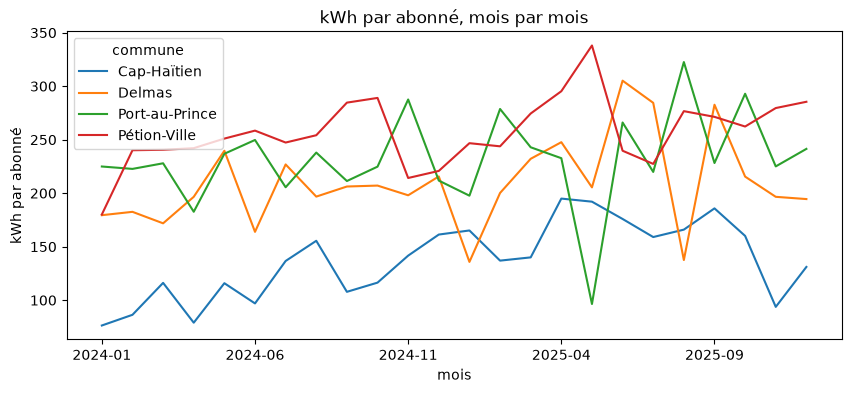

In [27]:
tab = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
tab["hausse_pct"] = (tab[2025] / tab[2024] - 1) * 100   # avant arrondi
tab = tab.sort_values("hausse_pct", ascending=False)
tab[[2024, 2025]] = (tab[[2024, 2025]] / 1e6).round(2)
tab["hausse_pct"] = tab["hausse_pct"].round(1)
print(tab)

par_mois = df.groupby(["mois", "commune"])["kwh_par_abonne"].mean().unstack()
par_mois.plot(figsize=(10, 4), title="kWh par abonné, mois par mois")
plt.ylabel("kWh par abonné")
plt.show()

**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

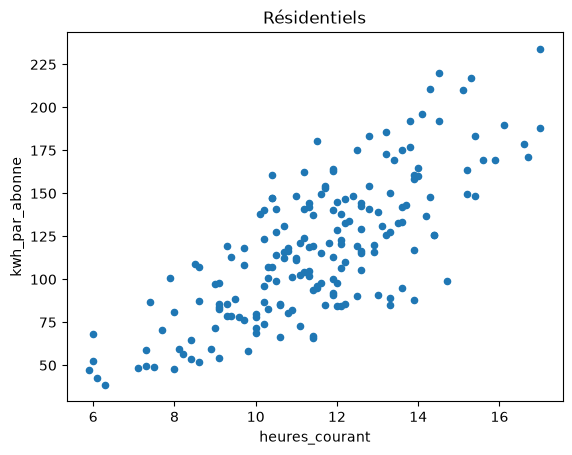

0.76
-0.15


In [28]:
res = df[df["type"] == "Résidentiel"]
res.plot.scatter(x="heures_courant", y="kwh_par_abonne", title="Résidentiels")
plt.show()
print(res["kwh_par_abonne"].corr(res["heures_courant"]).round(2))   # attendu : 0.76
print(res["kwh_par_abonne"].corr(res["temperature_c"]).round(2))    # attendu : -0.15

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

                 25%   50%   75%
commune                         
Cap-Haïtien      8.3  10.0  11.7
Delmas          10.1  11.9  13.0
Port-au-Prince  10.7  11.6  13.1
Pétion-Ville    10.4  11.6  13.0


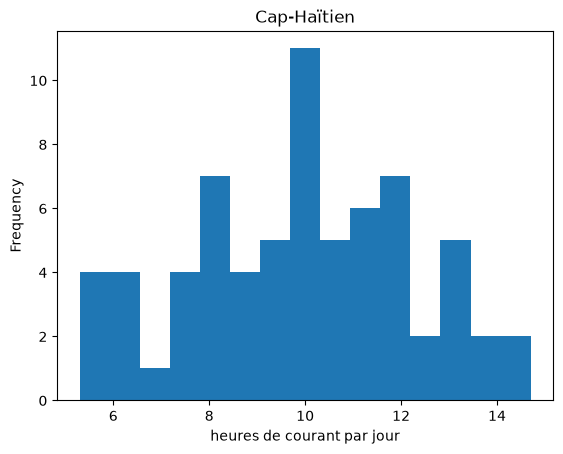

3
['Delmas 33', 'Carénage', 'Rue 15']


In [ ]:
print(df.groupby("commune")["heures_courant"].describe()[["25%", "50%", "75%"]].round(1))

df[df["commune"] == "Cap-Haïtien"]["heures_courant"].plot.hist(bins=15, title="Cap-Haïtien")
plt.xlabel("heures de courant par jour")
plt.show()

courtes = df[(df["annee"] == 2025) & (df["heures_courant"] < 8)]
print(len(courtes))                     
print(courtes["quartier"].tolist())       

**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [30]:
df.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780.0
56,2024-11,Centre-ville,Commercial,597730.0
88,2025-09,Delmas 33,Commercial,591420.0


**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

Pour les quartiers résidentiels, la consommation par abonné suit les heures de courant (corrélation 0.76) bien plus que la chaleur (corrélation -0.15 avec la température). Les écarts entre quartiers sont aussi nets : Centre-ville consomme 468.7 kWh par abonné, et Cap-Haïtien a vu sa consommation monter de 22.4 % entre 2024 et 2025. Mais une corrélation ne prouve pas une cause : elle ne dit pas que les heures de courant font consommer davantage, et elle ne concerne que les quartiers résidentiels.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.